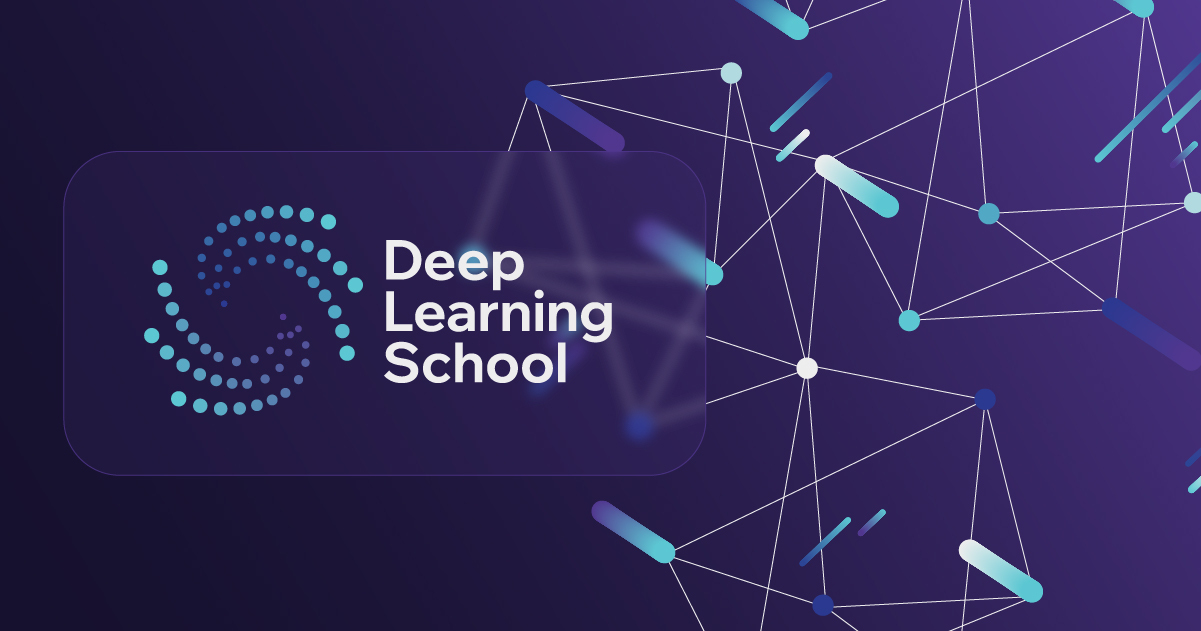

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание. Обучение языковой модели с помощью LSTM </b></h1>


В этом задании Вам предстоит обучить языковую модель с помощью рекуррентной нейронной сети. В отличие от семинарского занятия, Вам необходимо будет работать с отдельными словами, а не буквами.


Установим модуль ```datasets```, чтобы нам проще было работать с данными.

In [1]:
!pip install -q datasets huggingface_hub


Импорт необходимых библиотек

In [23]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import numpy as np
import matplotlib.pyplot as plt
import math

from tqdm.auto import tqdm
from datasets import load_dataset
from nltk.tokenize import sent_tokenize, word_tokenize
from sklearn.model_selection import train_test_split
import nltk

from collections import Counter
from typing import List

import seaborn
seaborn.set(palette='summer')

In [4]:
nltk.download('punkt')
nltk.download('punkt_tab')


[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [5]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

### Персистентное хранилище весов и результатов

In [6]:
import os
import io
import torch
from huggingface_hub import HfApi, login, hf_hub_download

HF_REPO_NAME = 'dls'
HF_SUBFOLDER = 'dls_part_2/weights/hw_language_modelling'

hf_token = None
try:
    from kaggle_secrets import UserSecretsClient
    user_secrets = UserSecretsClient()
    hf_token = user_secrets.get_secret('HF_TOKEN')
except Exception:
    pass

if not hf_token:
    raise RuntimeError(
        "HF_TOKEN не найден"
    )

login(token=hf_token, add_to_git_credential=False)
api = HfApi(token=hf_token)

user_info = api.whoami()
username = user_info.get('name') or user_info.get('preferred_username')
HF_REPO_ID = f"{username}/{HF_REPO_NAME}"
api.create_repo(repo_id=HF_REPO_ID, repo_type='model', private=True, exist_ok=True)

print(f"Hugging Face подключен: https://huggingface.co/{HF_REPO_ID}")
print(f"Путь для сохранения/загрузки: {HF_SUBFOLDER}/")

Hugging Face подключен: https://huggingface.co/libertman/dls
Путь для сохранения/загрузки: dls_part_2/weights/hw_language_modelling/


In [7]:
def save_experiment(name: str, model: torch.nn.Module, losses: list, perplexities: list):
    print(f"Выгрузка эксперимента '{name}' на Hugging Face ({HF_REPO_ID}/{HF_SUBFOLDER})...")
    
    weights_buf = io.BytesIO()
    torch.save(model.state_dict(), weights_buf)
    weights_buf.seek(0)
    api.upload_file(
        path_or_fileobj=weights_buf,
        path_in_repo=f"{HF_SUBFOLDER}/{name}_weights.pth",
        repo_id=HF_REPO_ID,
        repo_type="model",
        commit_message=f"Save {name} weights"
    )
    
    history_buf = io.BytesIO()
    torch.save({"losses": losses, "perplexities": perplexities}, history_buf)
    history_buf.seek(0)
    api.upload_file(
        path_or_fileobj=history_buf,
        path_in_repo=f"{HF_SUBFOLDER}/{name}_history.pt",
        repo_id=HF_REPO_ID,
        repo_type="model",
        commit_message=f"Save {name} history"
    )
    print(f"✓ Эксперимент '{name}' успешно сохранен в Hugging Face!")


def load_experiment(name: str, model: torch.nn.Module = None, device: str = 'cpu'):
    weights_filename = f"{HF_SUBFOLDER}/{name}_weights.pth"
    history_filename = f"{HF_SUBFOLDER}/{name}_history.pt"
    
    try:
        weights_path = hf_hub_download(repo_id=HF_REPO_ID, filename=weights_filename, repo_type="model")
        history_path = hf_hub_download(repo_id=HF_REPO_ID, filename=history_filename, repo_type="model")
        
        if model is not None:
            model.load_state_dict(torch.load(weights_path, map_location=device))
            print(f"✓ Веса '{name}' загружены из HF ({weights_filename})")
            
        history = torch.load(history_path, map_location="cpu")
        losses = history.get("losses", [])
        ppl = history.get("perplexities", [])
        best_ppl = min(ppl) if ppl else 0.0
        print(f"✓ История '{name}' загружена ({len(losses)} эпох, лучшая perplexity: {best_ppl:.2f})")
        return True, losses, ppl
    except Exception as e:
        print(f"Эксперимент '{name}' не найден на Hugging Face ({e}).")
        return False, [], []

## Подготовка данных

Воспользуемся датасетом imdb. В нем хранятся отзывы о фильмах с сайта imdb. Загрузим данные с помощью функции ```load_dataset```

In [9]:
# Загрузим датасет
dataset = load_dataset('stanfordnlp/imdb')

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

### Препроцессинг данных и создание словаря (1 балл)

Далее вам необходмо самостоятельно произвести препроцессинг данных и получить словарь или же просто ```set``` строк. Что необходимо сделать:

1. Разделить отдельные тренировочные примеры на отдельные предложения с помощью функции ```sent_tokenize``` из бибилиотеки ```nltk```. Каждое отдельное предложение будет одним тренировочным примером.
2. Оставить только те предложения, в которых меньше ```word_threshold``` слов.
3. Посчитать частоту вхождения каждого слова в оставшихся предложениях. Для деления предлоения на отдельные слова удобно использовать функцию ```word_tokenize```.
4. Создать объект ```vocab``` класса ```set```, положить в него служебные токены '\<unk\>', '\<bos\>', '\<eos\>', '\<pad\>' и vocab_size самых частовстречающихся слов.   

In [10]:
sentences = []
word_threshold = 32

for text in tqdm(dataset['train']['text'], desc="Collecting sentences"):
    clean_text = text.replace('<br />', ' ').replace('<br/>', ' ')
    for sent in sent_tokenize(clean_text):
        if len(word_tokenize(sent)) < word_threshold:
            sentences.append(sent)


In [11]:
print("Всего предложений:", len(sentences))

Всего предложений: 254301


Посчитаем для каждого слова его встречаемость.

In [12]:
words = Counter()

for sent in tqdm(sentences, desc="Counting words"):
    for word in word_tokenize(sent.lower()):
        words[word] += 1


Counting words:   0%|          | 0/254301 [00:00<?, ?it/s]

Добавим в словарь ```vocab_size``` самых встречающихся слов.

In [13]:
vocab = set()
vocab_size = 40000

special_tokens = {'<unk>', '<bos>', '<eos>', '<pad>'}
vocab.update(special_tokens)

for word, _ in words.most_common():
    if word not in special_tokens:
        vocab.add(word)
    if len(vocab) == vocab_size + 4:
        break


In [17]:
words.most_common()[:10]

[('.', 221072),
 ('the', 200332),
 (',', 151809),
 ('a', 98096),
 ('and', 94914),
 ('of', 83366),
 ('to', 79388),
 ('is', 74738),
 ('it', 66036),
 ('i', 61625)]

In [18]:
print("Всего слов в словаре:", len(vocab))

Всего слов в словаре: 40004


### Подготовка датасета (1 балл)

Далее, как и в семинарском занятии, подготовим датасеты и даталоадеры.

В классе ```WordDataset``` вам необходимо реализовать метод ```__getitem__```, который будет возвращать сэмпл данных по входному idx, то есть список целых чисел (индексов слов).

Внутри этого метода необходимо добавить служебные токены начала и конца последовательности, а также токенизировать соответствующее предложение с помощью ```word_tokenize``` и сопоставить ему индексы из ```word2ind```.

In [19]:
vocab = sorted(list(vocab))
word2ind = {char: i for i, char in enumerate(vocab)}
ind2word = {i: char for char, i in word2ind.items()}


In [20]:
class WordDataset:
    def __init__(self, sentences):
        self.data = sentences
        self.unk_id = word2ind['<unk>']
        self.bos_id = word2ind['<bos>']
        self.eos_id = word2ind['<eos>']
        self.pad_id = word2ind['<pad>']

    def __getitem__(self, idx: int) -> List[int]:
        tokens = word_tokenize(self.data[idx].lower())
        tokenized_sentence = (
            [self.bos_id]
            + [word2ind.get(token, self.unk_id) for token in tokens]
            + [self.eos_id]
        )
        
        return tokenized_sentence

    def __len__(self) -> int:
        return len(self.data)


In [21]:
def collate_fn_with_padding(
    input_batch: List[List[int]], pad_id=word2ind['<pad>']) -> torch.Tensor:
    seq_lens = [len(x) for x in input_batch]
    max_seq_len = max(seq_lens)

    new_batch = []
    for sequence in input_batch:
        for _ in range(max_seq_len - len(sequence)):
            sequence.append(pad_id)
        new_batch.append(sequence)

    sequences = torch.LongTensor(new_batch).to(device)

    new_batch = {
        'input_ids': sequences[:,:-1],
        'target_ids': sequences[:,1:]
    }

    return new_batch

In [22]:
train_sentences, temp_sentences = train_test_split(sentences, test_size=0.2, random_state=42)
eval_sentences, test_sentences = train_test_split(temp_sentences, test_size=0.5, random_state=42)

train_dataset = WordDataset(train_sentences)
eval_dataset = WordDataset(eval_sentences)
test_dataset = WordDataset(test_sentences)

batch_size = 128

train_dataloader = DataLoader(
    train_dataset, collate_fn=collate_fn_with_padding, batch_size=batch_size)

eval_dataloader = DataLoader(
    eval_dataset, collate_fn=collate_fn_with_padding, batch_size=batch_size)

test_dataloader = DataLoader(
    test_dataset, collate_fn=collate_fn_with_padding, batch_size=batch_size)

## Обучение и архитектура модели

Вам необходимо на практике проверить, что влияет на качество языковых моделей. В этом задании нужно провести серию экспериментов с различными вариантами языковых моделей и сравнить различия в конечной перплексии на тестовом множестве.

Возмоэные идеи для экспериментов:

* Различные RNN-блоки, например, LSTM или GRU. Также можно добавить сразу несколько RNN блоков друг над другом с помощью аргумента num_layers. Вам поможет официальная документация [здесь](https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html)
* Различные размеры скрытого состояния. Различное количество линейных слоев после RNN-блока. Различные функции активации.
* Добавление нормализаций в виде Dropout, BatchNorm или LayerNorm
* Различные аргументы для оптимизации, например, подбор оптимального learning rate или тип алгоритма оптимизации SGD, Adam, RMSProp и другие
* Любые другие идеи и подходы

После проведения экспериментов необходимо составить таблицу результатов, в которой описан каждый эксперимент и посчитана перплексия на тестовом множестве.

Учтите, что эксперименты, которые различаются, например, только размером скрытого состояния или количеством линейных слоев считаются, как один эксперимент.

Успехов!

### Функция evaluate (1 балл)

Заполните функцию ```evaluate```

In [28]:
def evaluate(model, criterion, eval_dataloader) -> float:
    """
    Calculate perplexity on validation dataloader.
    """

    model.eval()
    losses = []

    with torch.no_grad():
        for batch in eval_dataloader:
            logits = model(batch['input_ids']).flatten(start_dim=0, end_dim=1)
            loss = criterion(
                logits,
                batch['target_ids'].flatten()
            )
            losses.append(loss.item())

    mean_loss = sum(losses) / len(losses)
    perplexity = math.exp(mean_loss)

    return perplexity

### Train loop (1 балл)

Напишите функцию для обучения модели.

In [36]:
def train_model(
    model: nn.Module,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
    train_dataloader: DataLoader,
    eval_dataloader: DataLoader,
    num_epoch: int = 5,
    eval_steps: int = None,
    max_norm: float = None
):
    if eval_steps is None:
        eval_steps = len(train_dataloader) // 2

    losses = []
    perplexities = []

    for epoch in range(num_epoch):
        epoch_losses = []
        model.train()
        for i, batch in enumerate(tqdm(train_dataloader, desc=f'Training epoch {epoch}:')):
            optimizer.zero_grad()
            logits = model(batch['input_ids']).flatten(0, 1)
            loss = criterion(logits, batch['target_ids'].flatten())
            loss.backward()
            if max_norm is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm)
            optimizer.step()

            epoch_losses.append(loss.item())
            if i % eval_steps == 0:
                eval_ppl = evaluate(model, criterion, eval_dataloader)
                perplexities.append(eval_ppl)
                model.train()

        losses.append(sum(epoch_losses) / len(epoch_losses))

    return losses, perplexities


### Первый эксперимент (2 балла)

Определите архитектуру модели и обучите её.

In [30]:
class LanguageModel(nn.Module):
    def __init__(
        self, vocab_size: int, embedding_dim: int = 256, hidden_dim: int = 256
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.rnn = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)
        self.projection = nn.Linear(hidden_dim, vocab_size)

    def forward(self, input_batch: torch.Tensor) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)
        logits = self.projection(output)
        return logits


In [31]:
exp_name_1 = 'lstm_lm'
FORCE_RETRAIN_1 = False

model_1 = LanguageModel(
    vocab_size=len(vocab),
    embedding_dim=256,
    hidden_dim=256
).to(device)

criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(model_1.parameters(), lr=1e-3)

is_loaded, losses_1, ppl_1 = load_experiment(exp_name_1, model=model_1, device=device)

if is_loaded and not FORCE_RETRAIN_1:
    print(f"Эксперимент {exp_name_1} загружен из Hugging Face. Пропускаем обучение.")
else:
    print(f"Обучение модели {exp_name_1}...")
    losses_1, ppl_1 = train_model(
        model=model_1,
        optimizer=optimizer,
        criterion=criterion,
        train_dataloader=train_dataloader,
        eval_dataloader=eval_dataloader,
        num_epoch=5
    )
    save_experiment(exp_name_1, model_1, losses_1, ppl_1)

test_ppl_1 = evaluate(model_1, criterion, test_dataloader)
print(f"Perplexity на тестовой выборке ({exp_name_1}): {test_ppl_1:.2f}")

Эксперимент 'lstm_lm' не найден на Hugging Face (404 Client Error. (Request ID: Root=1-6ae631b1-17c144366fed699b712e4ded;c7a72ccd-147b-455b-bbff-e9d3bda60ba4)

Entry Not Found for url: https://huggingface.co/libertman/dls/resolve/main/dls_part_2/weights/hw_language_modelling/lstm_lm_weights.pth.).
Обучение модели lstm_lm...


Training epoch 0::   0%|          | 0/1590 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/1590 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/1590 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/1590 [00:00<?, ?it/s]

Training epoch 4::   0%|          | 0/1590 [00:00<?, ?it/s]

Выгрузка эксперимента 'lstm_lm' на Hugging Face (libertman/dls/dls_part_2/weights/hw_language_modelling)...


Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.
Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.


✓ Эксперимент 'lstm_lm' успешно сохранен в Hugging Face!
Perplexity на тестовой выборке (lstm_lm): 104.11


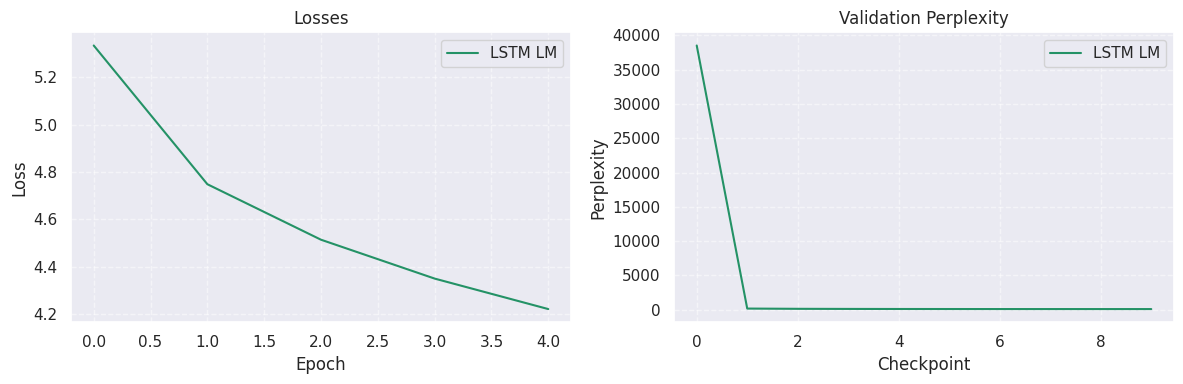

In [32]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(np.arange(len(losses_1)), losses_1, label='LSTM LM')
plt.title('Losses')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(np.arange(len(ppl_1)), ppl_1, label='LSTM LM')
plt.title('Validation Perplexity')
plt.xlabel('Checkpoint')
plt.ylabel('Perplexity')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

### Второй эксперимент (2 балла)

Здесь реализуется комплексное качественное улучшение архитектуры и пайплайна:
1. Связывание весов эмбеддингов и проекции: Матрица входных эмбеддингов и матрица выходного линейного слоя связываются. Это сокращает модель от избыточных параметров, исключает рассогласование входного и выходного векторных пространств и существенно ускоряет обучение. Не указано в экспериментах, но довольно интересный подход, захотелось применить.
2. Добавляются dropout на входе, межслойный dropout в LSTM и выходной dropout перед проекцией, что защищает модель от застревания на частых сочетаниях слов. Ну и плюс из-за повышения количества `num_layers` из 5 пункта есть риск переобучения, dropout также в этом спасает.
3. В nn.Embedding фиксируется `padding_idx`, гарантируя, что вектор `<pad>` останется строго нулевым и не будет накапливать паразитные градиенты.
4. Стабилизация градиентов Gradient Clipping. Защищает рекуррентную сеть от взрыва градиентов при BPTT. По-моему было в лекции про этот подход.
5. Двухслойный рекуррентный стек (`num_layers=2`): Первый слой извлекает локальные синтаксические паттерны, второй слой строит глобальный семантический контекст.


In [34]:
class ImprovedLanguageModel(nn.Module):
    def __init__(
        self, vocab_size: int, embedding_dim: int = 256, hidden_dim: int = 256,
        num_layers: int = 2, dropout: float = 0.25, pad_idx: int = 0
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.drop = nn.Dropout(dropout)
        self.rnn = nn.LSTM(
            embedding_dim, hidden_dim,
            num_layers=num_layers,
            dropout=dropout if num_layers > 1 else 0.0,
            batch_first=True
        )
        self.projection = nn.Linear(hidden_dim, vocab_size)

        if embedding_dim == hidden_dim:
            self.projection.weight = self.embedding.weight

    def forward(self, input_batch: torch.Tensor) -> torch.Tensor:
        embeddings = self.drop(self.embedding(input_batch))
        output, _ = self.rnn(embeddings)
        logits = self.projection(self.drop(output))
        return logits

In [37]:
exp_name_2 = 'improved_lstm_lm'
FORCE_RETRAIN_2 = False

model_2 = ImprovedLanguageModel(
    vocab_size=len(vocab),
    embedding_dim=256,
    hidden_dim=256,
    num_layers=2,
    dropout=0.25,
    pad_idx=word2ind['<pad>']
).to(device)

criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer = torch.optim.Adam(model_2.parameters(), lr=1e-3)

is_loaded, losses_2, ppl_2 = load_experiment(exp_name_2, model=model_2, device=device)

if is_loaded and not FORCE_RETRAIN_2:
    print(f"Эксперимент {exp_name_2} загружен из Hugging Face. Пропускаем обучение.")
else:
    print(f"Обучение модели {exp_name_2}...")
    losses_2, ppl_2 = train_model(
        model=model_2,
        optimizer=optimizer,
        criterion=criterion,
        train_dataloader=train_dataloader,
        eval_dataloader=eval_dataloader,
        num_epoch=5,
        max_norm=5.0
    )
    save_experiment(exp_name_2, model_2, losses_2, ppl_2)

test_ppl_2 = evaluate(model_2, criterion, test_dataloader)
print(f"Perplexity на тестовой выборке ({exp_name_2}): {test_ppl_2:.2f}")


Эксперимент 'improved_lstm_lm' не найден на Hugging Face (404 Client Error. (Request ID: Root=1-6ae63ab2-7975524f0012713954c72ac3;ad9d7f2e-03f4-4af1-84e0-f8a66b111886)

Entry Not Found for url: https://huggingface.co/libertman/dls/resolve/main/dls_part_2/weights/hw_language_modelling/improved_lstm_lm_weights.pth.).
Обучение модели improved_lstm_lm...


Training epoch 0::   0%|          | 0/1590 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/1590 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/1590 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/1590 [00:00<?, ?it/s]

Training epoch 4::   0%|          | 0/1590 [00:00<?, ?it/s]

Выгрузка эксперимента 'improved_lstm_lm' на Hugging Face (libertman/dls/dls_part_2/weights/hw_language_modelling)...


Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.
Uploading files as a binary IO buffer is not supported by Xet Storage. Falling back to HTTP upload.


✓ Эксперимент 'improved_lstm_lm' успешно сохранен в Hugging Face!
Perplexity на тестовой выборке (improved_lstm_lm): 115.96


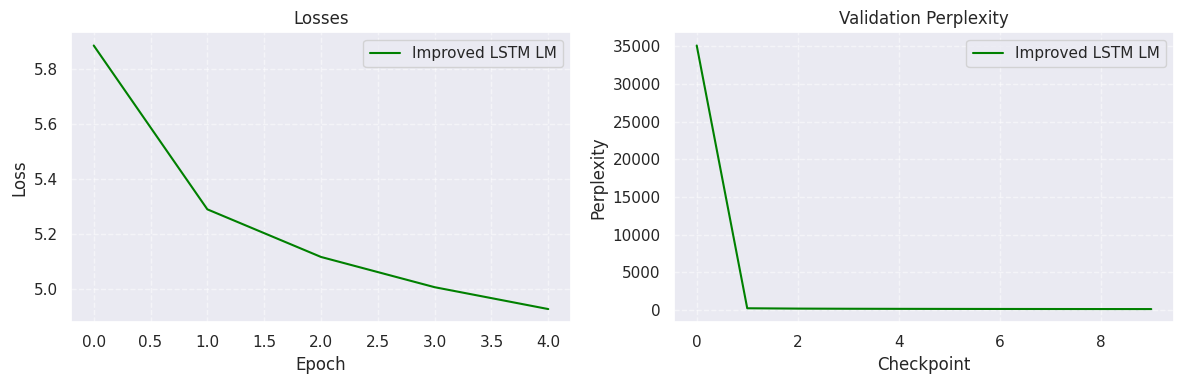

In [38]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(np.arange(len(losses_2)), losses_2, color='green', label='Improved LSTM LM')
plt.title('Losses')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(np.arange(len(ppl_2)), ppl_2, color='green', label='Improved LSTM LM')
plt.title('Validation Perplexity')
plt.xlabel('Checkpoint')
plt.ylabel('Perplexity')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

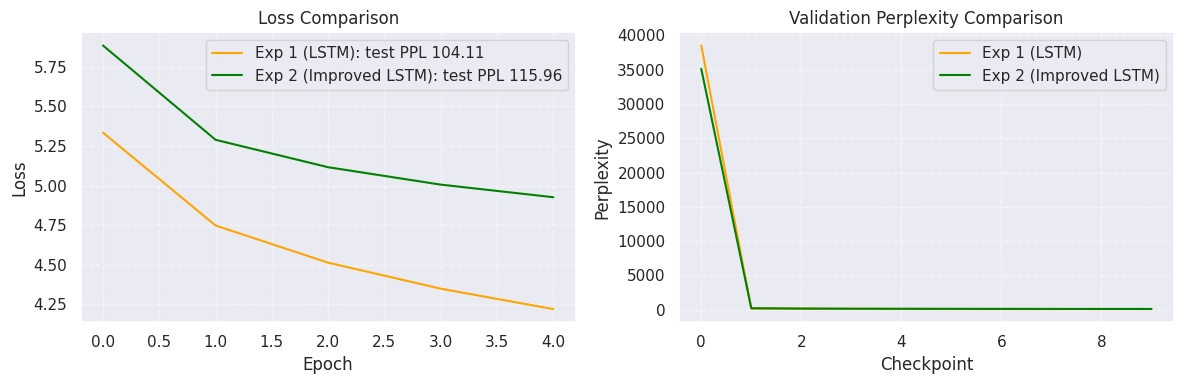

Эксперимент                    | Тестовая Perplexity 
-------------------------------------------------------
1. Baseline LSTM               | 104.11              
2. Improved LSTM (Tied+Drop+Clip) | 115.96              


In [40]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(np.arange(len(losses_1)), losses_1, color='orange', label=f'Exp 1 (LSTM): test PPL {test_ppl_1:.2f}')
plt.plot(np.arange(len(losses_2)), losses_2, color='green', label=f'Exp 2 (Improved LSTM): test PPL {test_ppl_2:.2f}')
plt.title('Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(np.arange(len(ppl_1)), ppl_1, color='orange', label='Exp 1 (LSTM)')
plt.plot(np.arange(len(ppl_2)), ppl_2, color='green', label='Exp 2 (Improved LSTM)')
plt.title('Validation Perplexity Comparison')
plt.xlabel('Checkpoint')
plt.ylabel('Perplexity')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

print(f"{'Эксперимент':<30} | {'Тестовая Perplexity':<20}")
print("-" * 55)
print(f"{'1. Baseline LSTM':<30} | {test_ppl_1:<20.2f}")
print(f"{'2. Improved LSTM (Tied+Drop+Clip)':<30} | {test_ppl_2:<20.2f}")

### Отчет

В ходе работы были обучены и сопоставлены две рекуррентные языковые модели на датасете IMDB со словарем в 40 004 токена:
1. Baseline LSTM (1 слой, hidden=256, embedding=256, без регуляризации): тестовая perplexity 104.11 (loss 4.64).
2. Improved LSTM (2 слоя, hidden=256, embedding=256, Weight Tying, Dropout=0.25, Gradient Clipping): тестовая perplexity 115.96 (loss 4.75).

Во втором эксперименте комплекс улучшений привел к более плавной и стабильной сходимости на графиках без скачков функции потерь благодаря клиппингу градиентов, однако итоговая перплексия за 5 эпох оказалась выше базовой (115.96 против 104.11).

Основная причина в том, что добавление двух слоев, связывания весов и трех точек применения Dropout (на входе, между слоями и перед выходом) существенно усилило регуляризацию и замедлило скорость обучения. За фиксированные 5 эпох более сложная и зарегулированная модель просто не успела сойтись, в то время как простая базовая модель без сопротивления быстрее минимизировала функцию потерь на частых словах. Кроме того, связывание весов при небольшой размерности 256 накладывает жесткое ограничение на ранг матрицы проекции для словаря из 40 000 классов.

Графики обучения подтверждают эту динамику: у второй модели кривые функции потерь и перплексии убывают монотонно и устойчиво, но к 5-й эпохе еще не вышли на плато, что свидетельствует о потенциале дальнейшего обучения (в принципе и у первой модели тоже, нужно смотреть на большее количество эпох)

Для дальнейшего улучшения качества языковой модели целесообразно:
1. Увеличить число эпох обучения до 10-15
2. Увеличить размерность эмбеддингов и скрытого состояния до 512, чтобы расширить емкость пространства представлений для словаря.
3. Перейти со словарной токенизации на токенизацию подстрок, что устранит редкие токены и сократит размер словаря.
4. Использовать трансформерную архитектуру, где механизм внимания снимает ограничения рекуррентного узкого горлышка.